# Makemore from Scratch

**Loading the data.** `names.txt` has one name per line. `.read().splitlines()` gives a plain Python list of strings. This list is the whole training set. Everything below is just a way of learning the patterns in it.

In [1]:
words = open('../data/names.txt').read().splitlines()

**Sanity-check the data.** Always look before you model. We have 32,033 names, between 2 and 15 characters long. Each name contains several training examples. For `isabella`, the model should learn that `i` is likely to start a name, `s` often follows `i`, and the name can end after `a`.

In [2]:
print(f"Total words: {len(words)}")
print(f"Min length: {min(len(w) for w in words)}, Max length: {max(len(w) for w in words)}")

Total words: 32033
Min length: 2, Max length: 15


In [3]:
print(words[:10])

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']


### Starting with a Bigram Language Model (Predict just the next character)

**Counting bigrams.** A bigram model predicts the next character using only the *previous* character. "Training" it just means counting how often each pair appears.

- `['<S>'] + list(w) + ['<E>']` wraps each name in start and end markers. The end marker is how the model learns when to stop.
- `zip(chs, chs[1:])` is a neat way to walk consecutive pairs: it pairs the list with itself shifted by one.
- The dictionary maps `(first, second)` to its count.

In [4]:
# We want to count how often each occurrence happens:
b = {}

# We just get consecutive elements in words. For each word we wrap them in a start and end token.
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1

**Reading the counts.** Sorting by count shows what the data is like. Names most often end in `n` or `a`, and the most common starting letters are `a` and `k`. The model will learn exactly these statistics and nothing more.

In [5]:
# Looking at the top 10 most common bigrams:
sorted(b.items(), key=lambda kv: kv[1], reverse=True)[:10]

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963)]

**Moving to tensors.** A dictionary of pairs is awkward to do math on. A 2D tensor lets us normalize every row at once, and the same structure carries over to the neural-net version later.

In [6]:
import torch

**Characters to integers.** Tensors are indexed by numbers, so we need a mapping.

- The 26 letters get indices 1 to 26 (sorted, so it's deterministic).
- We use one special token `.` at index 0 for both start and end. A `.` at the start of a pair means "name begins", and a `.` at the end means "name ends". That's simpler than two separate tokens.
- `itos` is the inverse mapping, used later to turn samples back into text.

In [7]:
# Create a lookup table to map characters to integers and vice versa
chars = sorted(list(set(''.join(words))))  # Get unique characters and sort them
stoi = {s:i+1 for i,s in enumerate(chars)}  # String to integer mapping
stoi['.'] = 0  # Special token
# Inverse mapping from integer to string
itos = {i:s for s,i in stoi.items()}

**The count table.** `N[i, j]` is how many times character `j` followed character `i`. Rows are the current character and columns are the next one. This is the same data as the dictionary, in a form we can do math on.

In [8]:
# Store the bigram counts in a tensor of shape (27, 27)
N = torch.zeros(27, 27, dtype=torch.int32) # Put the input into a tensor of shape (27, 27)

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

**Looking at it.** Row 0 shows how names start, and column 0 shows how they end. Notice how uneven the counts are, which is the structure the model captures. Plot your data whenever you can, because patterns and mistakes show up quickly.

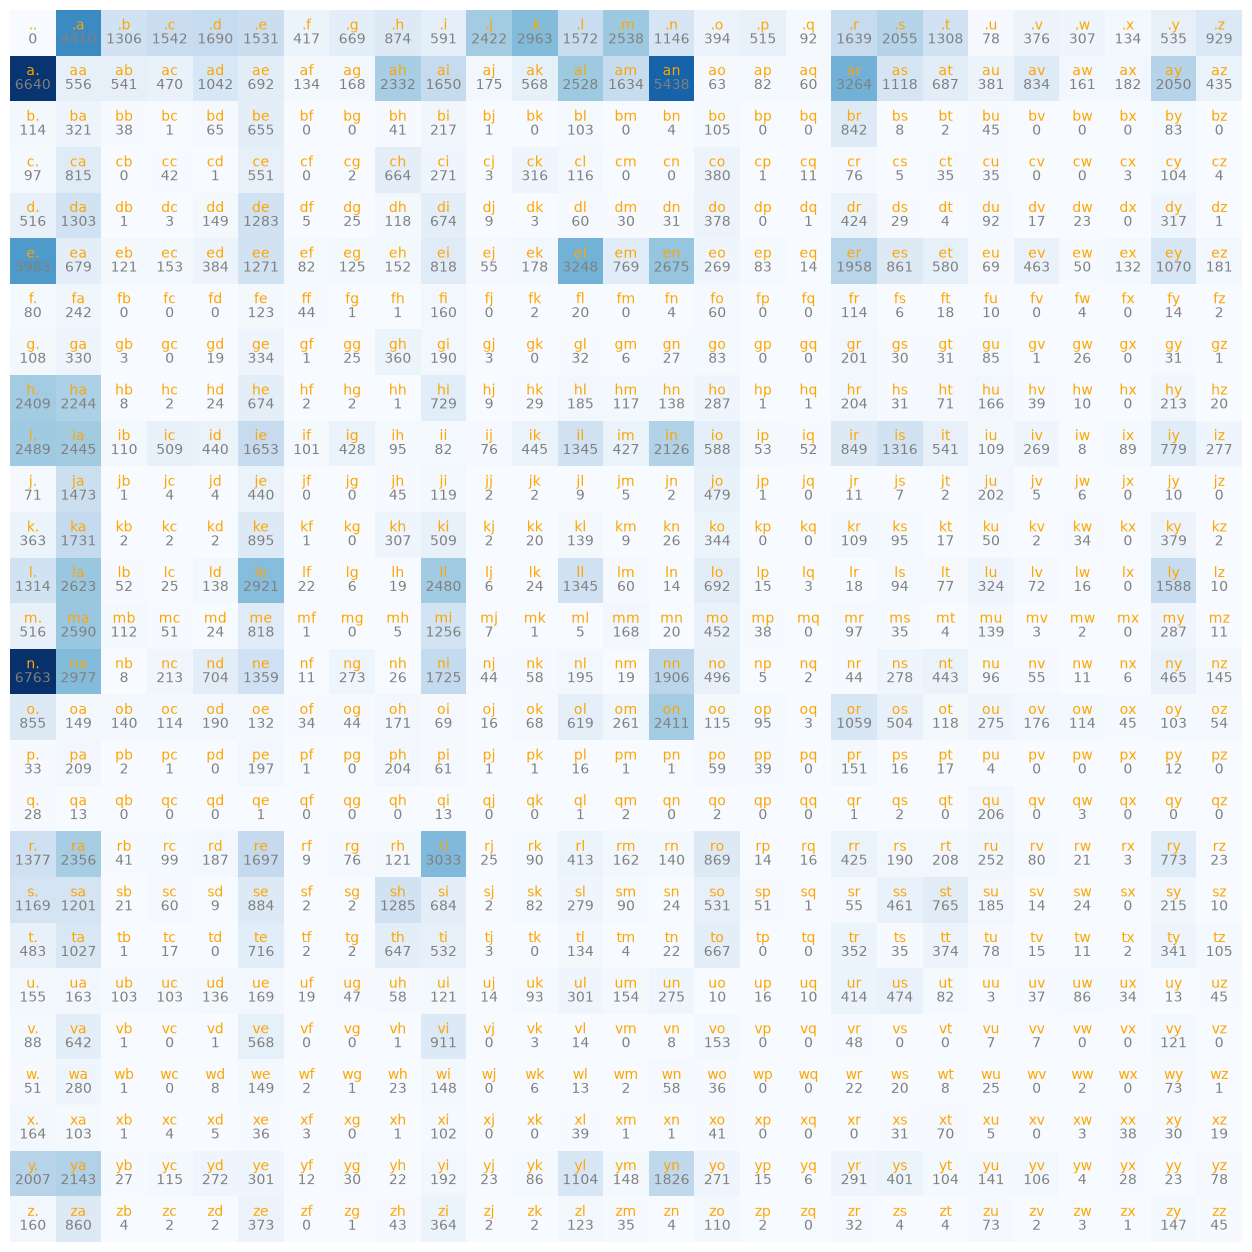

In [9]:
# Visualize the bigram counts as a heatmap
from matplotlib import pyplot as plt
plt.figure(figsize=(16, 16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha='center', va='bottom', color='orange')
        plt.text(j, i, N[i,j].item(), ha='center', va='top', color='gray')
plt.axis('off');

**From counts to probabilities.** Take the first row (what follows `.`, i.e. first letters). Dividing by its sum turns counts into a probability distribution that adds up to 1. For example, about 14% of names start with `a`, and about 9% start with `k`. `.float()` is needed because integer tensors can't be divided into fractions.

In [10]:
p = N[0].float()
p = p / p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

**Sampling once.** `torch.multinomial` draws an index according to the probabilities, so likely letters come up more often but unlikely ones still can.

The `Generator` with a fixed seed makes this reproducible: the same seed and the same calls give the same draws. The seed value itself is arbitrary. This is the single draw that gave `c`.

In [11]:
g = torch.Generator().manual_seed(2147483647)  # Seed for reproducibility
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()  # Sample 1 index from the distribution
itos[ix]

'c'

**Normalizing every row at once.** `P.sum(1, keepdim=True)` gives a `(27, 1)` column of row sums, and dividing `(27, 27)` by `(27, 1)` broadcasts so each row is divided by its own sum.

`keepdim=True` matters. Without it the sum has shape `(27,)`, which broadcasts across the *columns* instead. That would run without any error and silently give wrong probabilities, which is the classic broadcasting bug.

In [12]:
P = N.float()
P /= P.sum(1, keepdim=True)  # Normalize each row to sum to 1
# NOTE: This does an element-wise division, as defined by broadcasting rules in pytorch

**Check your work.** A row of probabilities must add up to 1. It's worth checking all rows at once with `P.sum(1)`, because a single check would not catch a bug that only affects some rows.

In [13]:
P[0].sum() # Normalized the rows -> keepdim is crucial because otherwise we create a row vector that normalizes the columns instead.

tensor(1.)

**Generating names.** Start at `.` (index 0). Look up that row of `P`, sample the next character, then use *that* character's row for the following sample. Stop when we draw `.` again.

Look at the output. Short names like `ka.` and `da.` look plausible, but `ftlspihinivenvorhlasu.` does not. The model only sees the single previous character, so it has no idea how long the name has gotten or what came before. That's the limit of a bigram model, and it's why the next steps use more context and a loss function to measure quality.

In [14]:
g = torch.Generator().manual_seed(2147483647)  # Seed for reproducibility

for i in range(20):
    out = []
    ix = 0
    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break

    print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.
ka.
emimmsade.
enkaviyny.
ftlspihinivenvorhlasu.
dsor.
br.
jol.
pen.
aisan.
ja.
